# Graph-Routed Contextual Atlas-DeePC

> **Trigger-free follow-up:** `pure_contextual_atlas_deepc.ipynb` replaces the global codebook with chart-local future modes and raises pure always-on contextual success from 444/500 to 463/500, above the 443/500 physical Atlas.

This notebook records the frozen Reacher **contextual Atlas-DeePC** method in the same deployment-oriented format as `baseline_graph_routed_atlas_deepc.ipynb`. The controller remains DeePC, not MPC: every optimized trajectory is a linear combination of columns of a cached offline behavioral basis.

The method keeps the 48-chart physical atlas for localization, transition-graph routing, and waypoint construction. It adds 128 contextual prototypes learned offline from normalized past output $Y_p$ and $Q$-weighted future output $Y_f$. Nominal control uses the current physical-chart basis. After a causal terminal stall, the controller scores only the 128 prototypes and permanently switches to the selected cached contextual basis. It never scans all Hankel columns or rebuilds an SVD online.

In [1]:
import json
import os
import sys
from dataclasses import asdict
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', '/tmp/atlas_deepc_mpl')
os.environ.setdefault('LOKY_MAX_CPU_COUNT', '1')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Image, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "baseline_atlas_deepc.py").is_file())
SRC = ROOT / 'src'
sys.path.insert(0, str(SRC))

import routed_deepc_experiment as routed
import contextual_cluster_atlas_experiment as contextual

DATA_PATH = ROOT / 'data' / 'select_iid_offline_hankel.npy'
RESULT_ROOT = ROOT / 'experiments' / 'routed_deepc_iid'
PHYSICAL_ATLAS_DIR = RESULT_ROOT / 'clustering_jointconfig48_fresh211_310'
BASELINE_EVAL_DIR = RESULT_ROOT / 'clustering_jointconfig48_baseline_cache'
DEV_CONTEXTUAL_DIR = RESULT_ROOT / 'contextual_cluster_dev_global128_triggered'
EVAL_CONTEXTUAL_DIR = RESULT_ROOT / 'contextual_cluster_eval211_710_global128_triggered'
DASHBOARD_DIR = RESULT_ROOT / 'contextual_cluster_dashboard_videos'
BASELINE_DASHBOARD_DIR = RESULT_ROOT / 'contextual_rescue_baseline_dashboards'

required_paths = [
    DATA_PATH,
    PHYSICAL_ATLAS_DIR / 'behavioral_atlas.npz',
    BASELINE_EVAL_DIR / 'summary.json',
    DEV_CONTEXTUAL_DIR / 'summary.json',
    EVAL_CONTEXTUAL_DIR / 'summary.json',
    EVAL_CONTEXTUAL_DIR / 'contextual_cluster_atlas.npz',
    RESULT_ROOT / 'physical48_chart_configuration_clouds.png',
    RESULT_ROOT / 'physical48_atlas_topology.png',
]
assert all(path.exists() for path in required_paths), [path for path in required_paths if not path.exists()]
print('Project root:', ROOT)

Project root: /Users/kumiko/Projects/atlas_deepc_reacher


## 1. Triggered contextual DeePC formulation

Let $B^{\mathrm{phys}}_{k_t}$ be the cached rank-60 basis of the measured physical chart $k_t$. Contextual K-means learns prototypes $c=1,\ldots,128$ in the offline embedding

$$
\xi_i=\begin{bmatrix}
Y_{p,i}^{\mathrm{norm}}/\sqrt{\dim Y_p}\\
Q^{1/2}Y_{f,i}^{\mathrm{norm}}/\|Q^{1/2}\|_F
\end{bmatrix}.
$$

For each prototype, its 200 nearest complete Hankel columns define an overlapping support $\mathcal J_c$ and cached affine basis

$$
A_c=(\bar h_c,B^{\mathrm{ctx}}_c,g_c^{\min},g_c^{\max}),
\qquad
B^{\mathrm{ctx}}_c=\operatorname{SVD}_{60}(H(:,\mathcal J_c)-\bar h_c).
$$

The terminal-stall trigger is causal: the exact target reference must be latched, error must exceed 1 cm, and progress over 15 steps must be below 1 mm. The matrix supplied to DeePC is

$$
B_t=\begin{cases}
B^{\mathrm{phys}}_{k_t}, & t<\tau,\\
B^{\mathrm{ctx}}_{c_t^\star}, & t\geq\tau,
\end{cases}
\qquad
c_t^\star=\arg\min_c\left[
z(\|\bar Y_{p,c}-y_{\mathrm{ini},t}\|_2)
+z(\|\bar Y_{f,c}-r_t\|_Q)
\right].
$$

The physical graph continues to construct references after the trigger. It never supplies actions; the same constrained DeePC QP computes every input.

In [2]:
dev_summary = json.loads((DEV_CONTEXTUAL_DIR / 'summary.json').read_text())
evaluation_summary = json.loads((EVAL_CONTEXTUAL_DIR / 'summary.json').read_text())
baseline_summary = json.loads((BASELINE_EVAL_DIR / 'summary.json').read_text())

development_runs = dev_summary['results']
evaluation_runs = evaluation_summary['results']
evaluation_by_seed = {int(row['seed']): row for row in evaluation_runs}
evaluation_seeds = sorted(evaluation_by_seed)
assert evaluation_seeds == list(range(211, 711))
evaluation_runs = [evaluation_by_seed[seed] for seed in evaluation_seeds]

config = routed.RoutedDeePCConfig(**evaluation_summary['config'])
cluster_config = contextual.ContextualClusterConfig(**evaluation_summary['contextual_cluster'])
H = np.load(DATA_PATH, mmap_mode='r')
physical_atlas = routed.load_atlas(PHYSICAL_ATLAS_DIR / 'behavioral_atlas.npz')
artifact = contextual.load_contextual_cluster_atlas(
    EVAL_CONTEXTUAL_DIR / 'contextual_cluster_atlas.npz'
)

assert config.clusters == 48
assert config.svd_rank == 60
assert cluster_config.contextual_clusters == 128
assert cluster_config.support_columns == 200
assert cluster_config.activation_mode == 'triggered'
assert artifact['matrix_bases'].shape == (128, H.shape[0], 60)
assert artifact['support_indices'].shape == (128, 200)

print('Offline Hankel shape:', H.shape)
print('Physical routing charts:', config.clusters)
print('Contextual prototypes:', cluster_config.contextual_clusters)
print('Complete columns per contextual basis:', cluster_config.support_columns)
print('Cached contextual basis shape:', artifact['matrix_bases'].shape)
print('Trigger: terminal reference, error > 1 cm, progress < 1 mm over 15 steps')
print('Evaluation panel: 500 seeds (211-710)')
print('Online full-column search / online SVD / fitted dynamics: False / False / False')

Offline Hankel shape: (144, 37800)
Physical routing charts: 48
Contextual prototypes: 128
Complete columns per contextual basis: 200
Cached contextual basis shape: (128, 144, 60)
Trigger: terminal reference, error > 1 cm, progress < 1 mm over 15 steps
Evaluation panel: 500 seeds (211-710)
Online full-column search / online SVD / fitted dynamics: False / False / False


## 2. Inspecting the two offline atlases

### Physical routing atlas

The 48 disjoint physical charts are unchanged from the baseline method. They localize the latest arm configuration and provide graph nodes, graph transitions, and waypoint medoids. They remain active for routing throughout every contextual deployment.

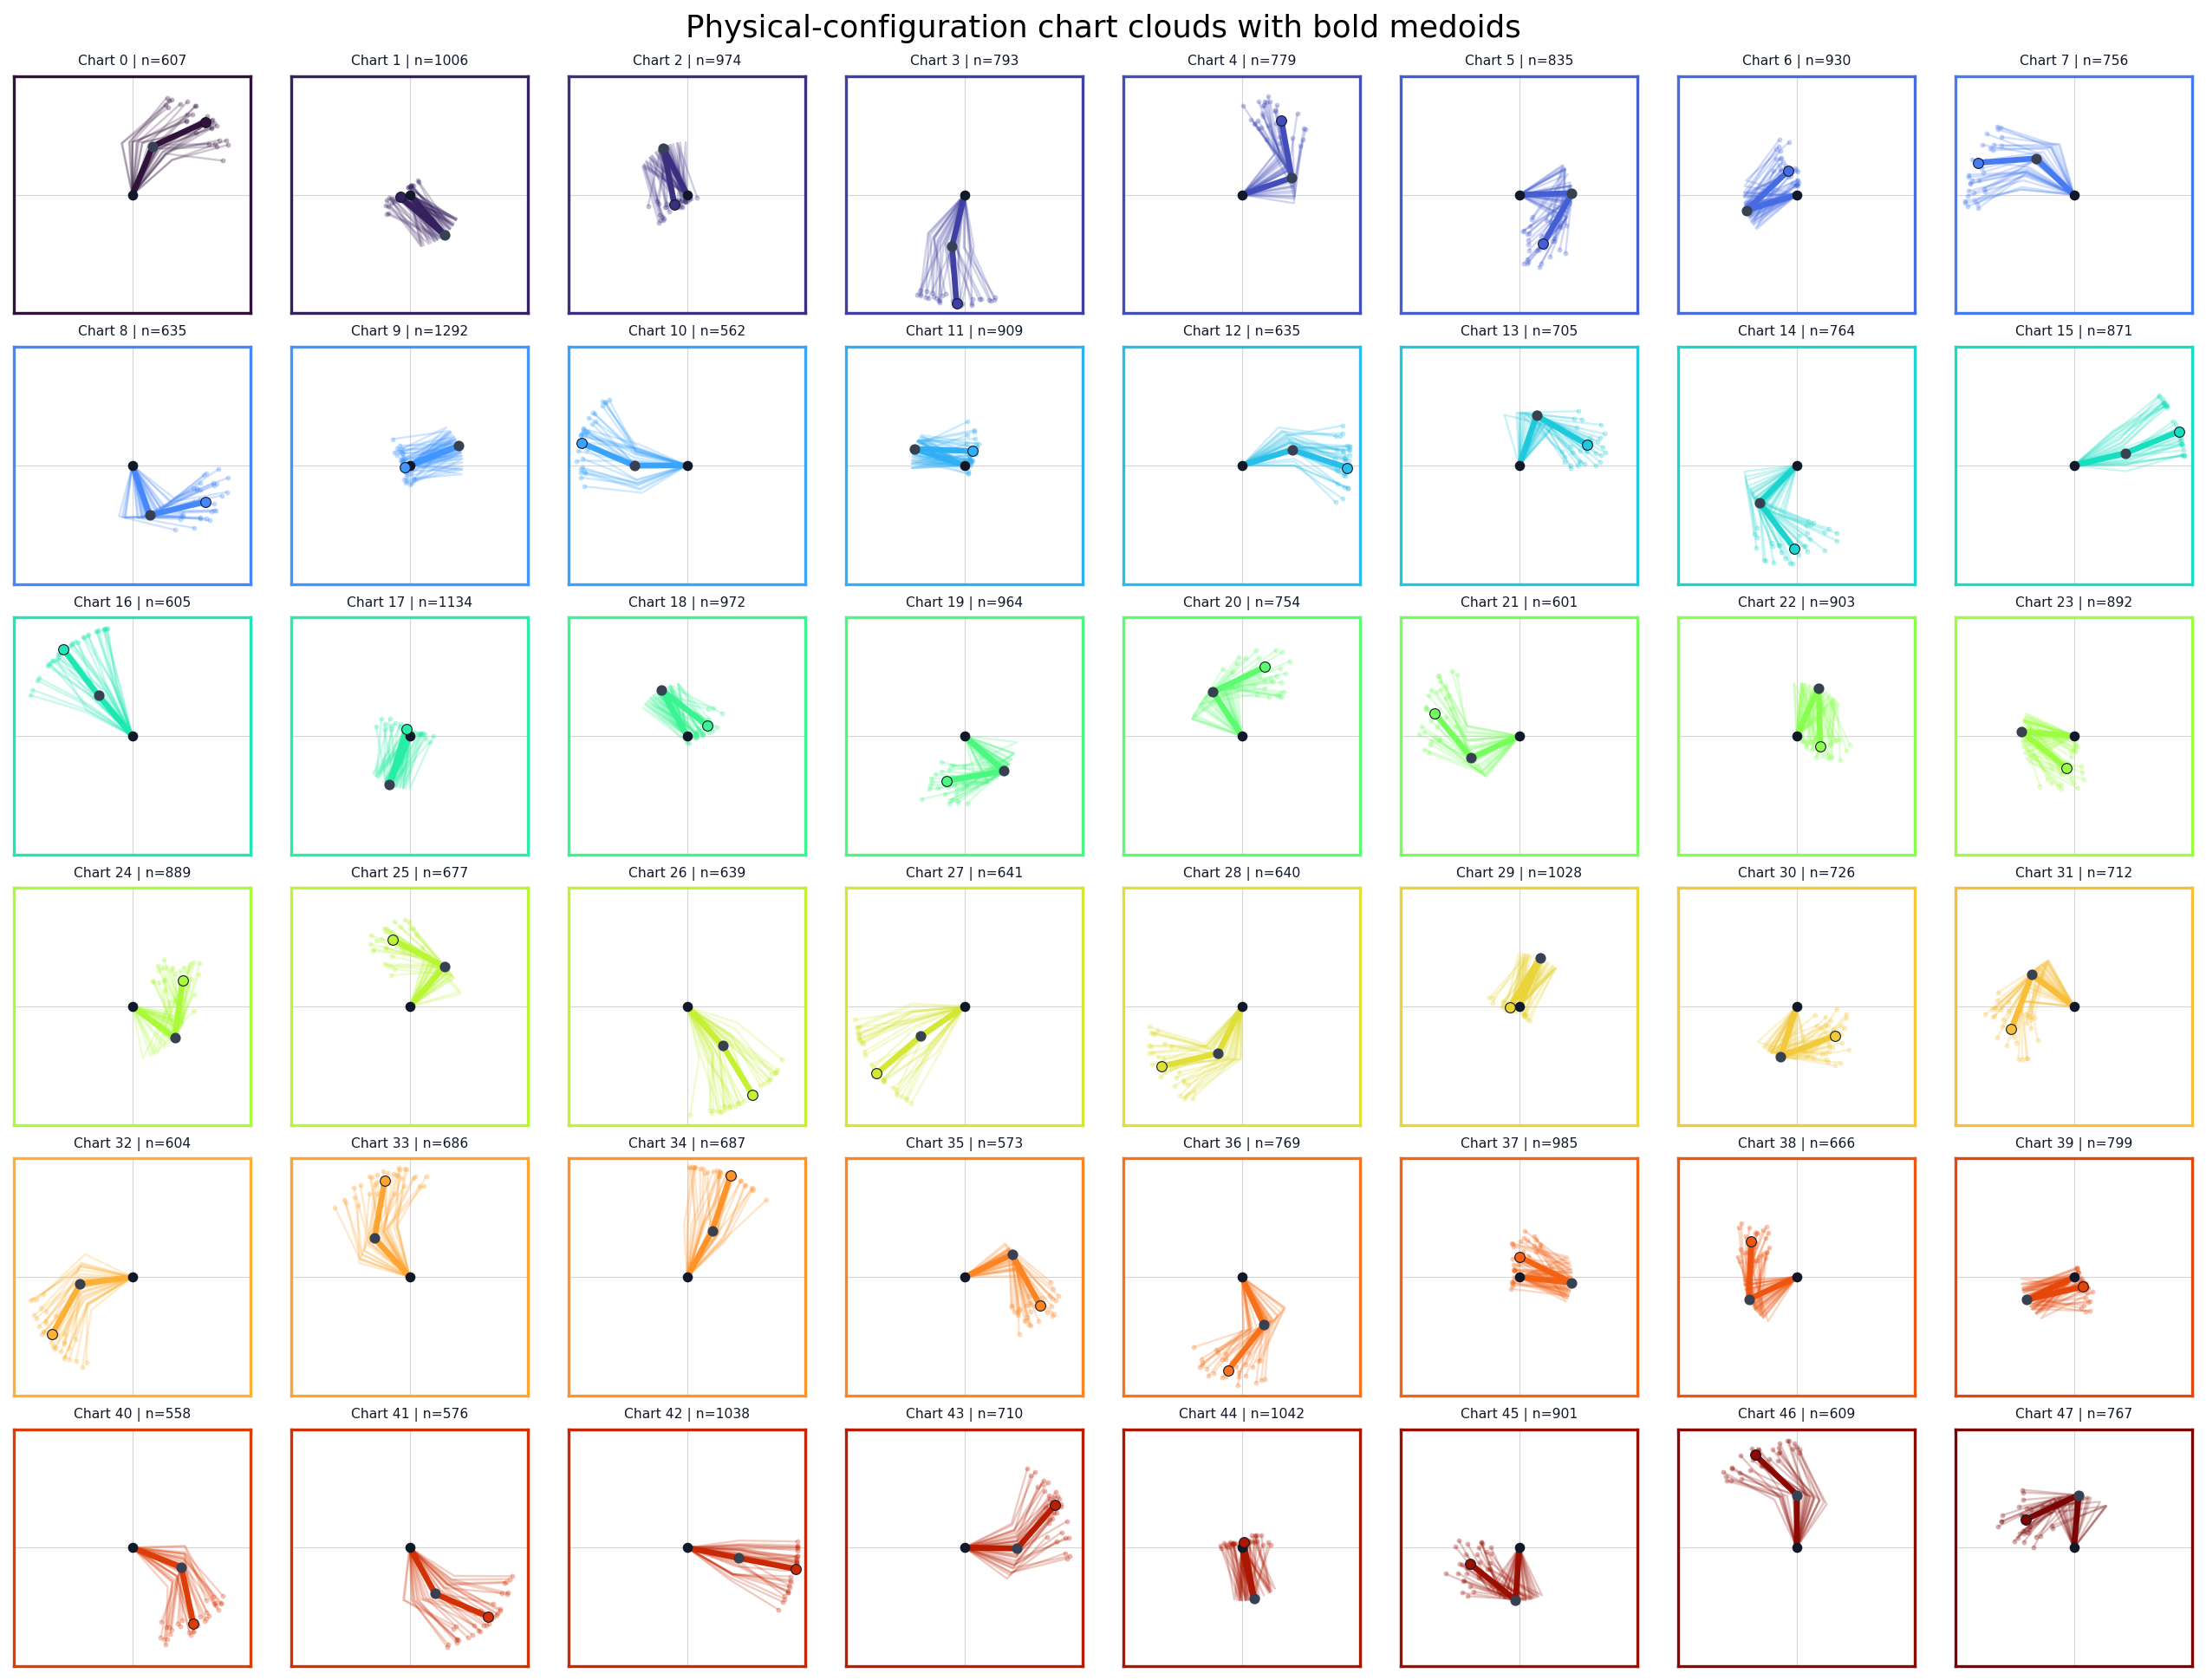

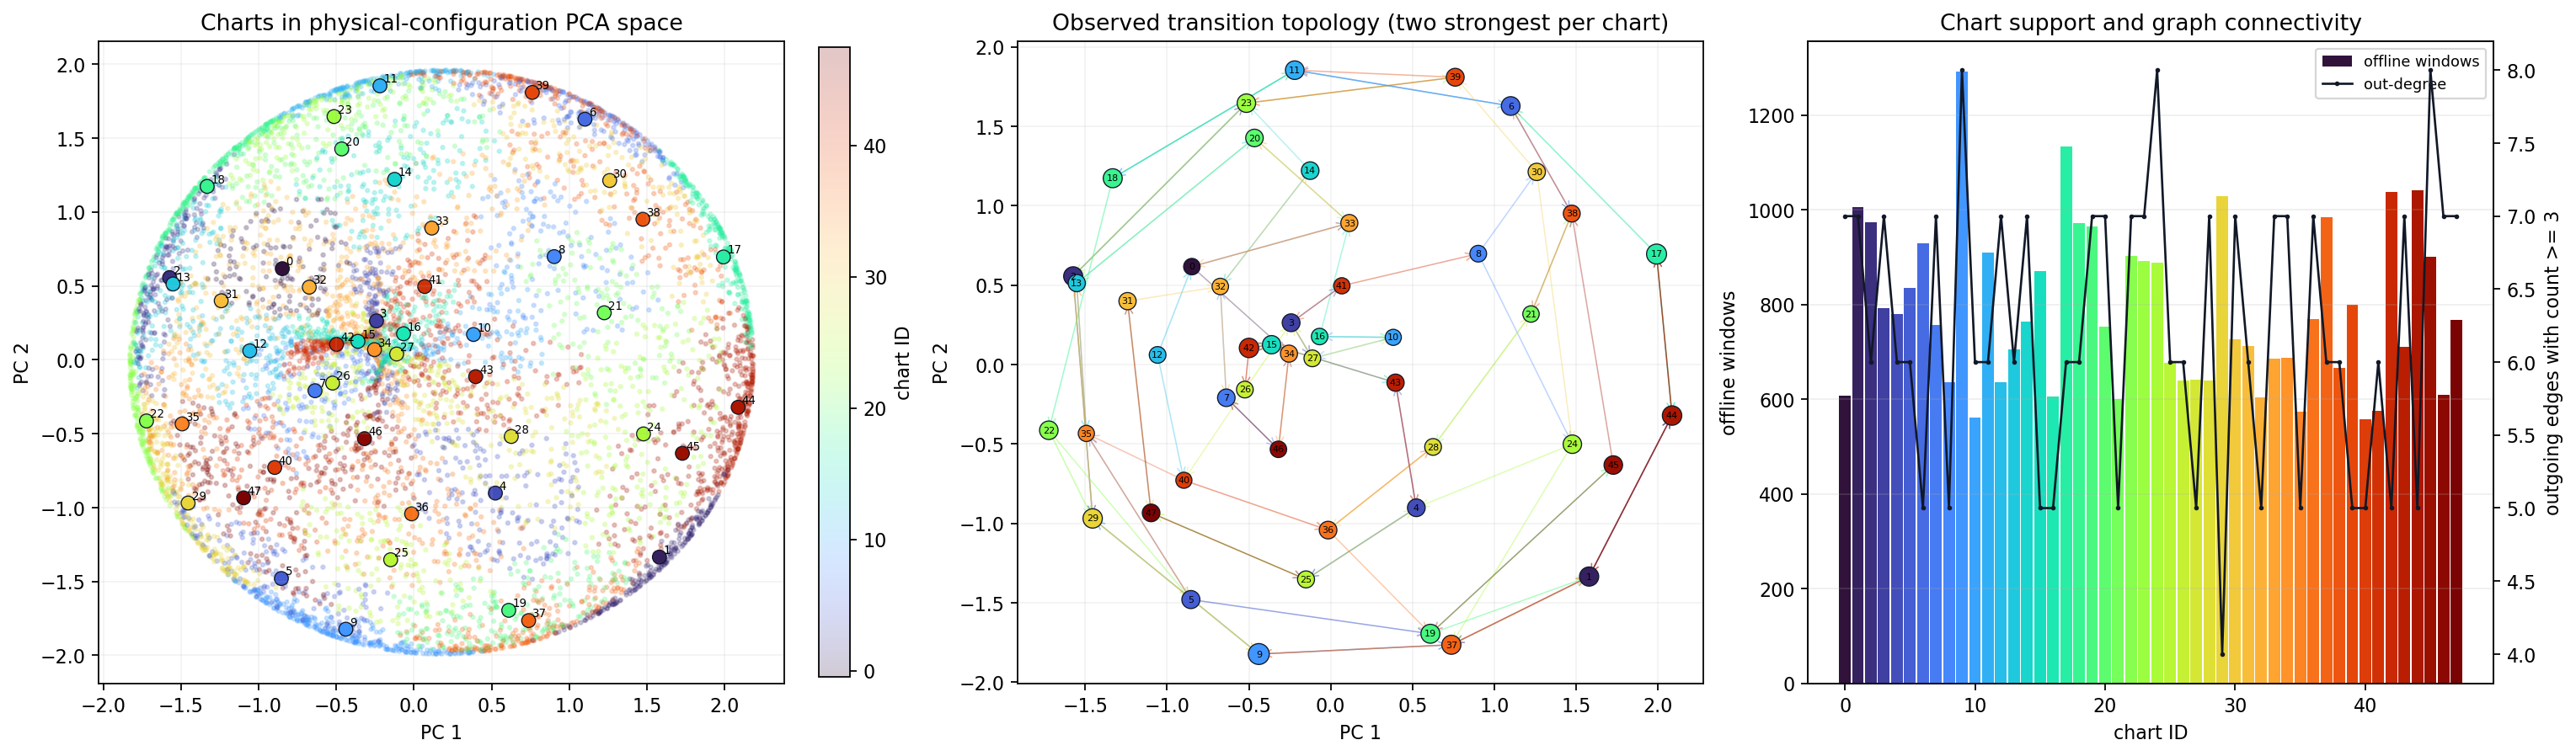

In [3]:
display(Image(filename=str(RESULT_ROOT / 'physical48_chart_configuration_clouds.png')))
display(Image(filename=str(RESULT_ROOT / 'physical48_atlas_topology.png')))

### Contextual basis atlas

The 128 contextual prototypes do not represent single static arm postures. Each prototype represents a local **past-to-future behavioral context**. In every panel below, shallow blue arms show current postures at the end of $Y_p$, shallow orange arms show terminal postures at the end of $Y_f$, and the bold pair is the support member nearest the contextual prototype. The arrow connects its current and future fingertip positions.

Every panel uses 200 complete $U_p,U_f,Y_p,Y_f$ support columns. Because supports are the nearest columns to each prototype rather than disjoint K-means memberships, contextual charts may overlap.

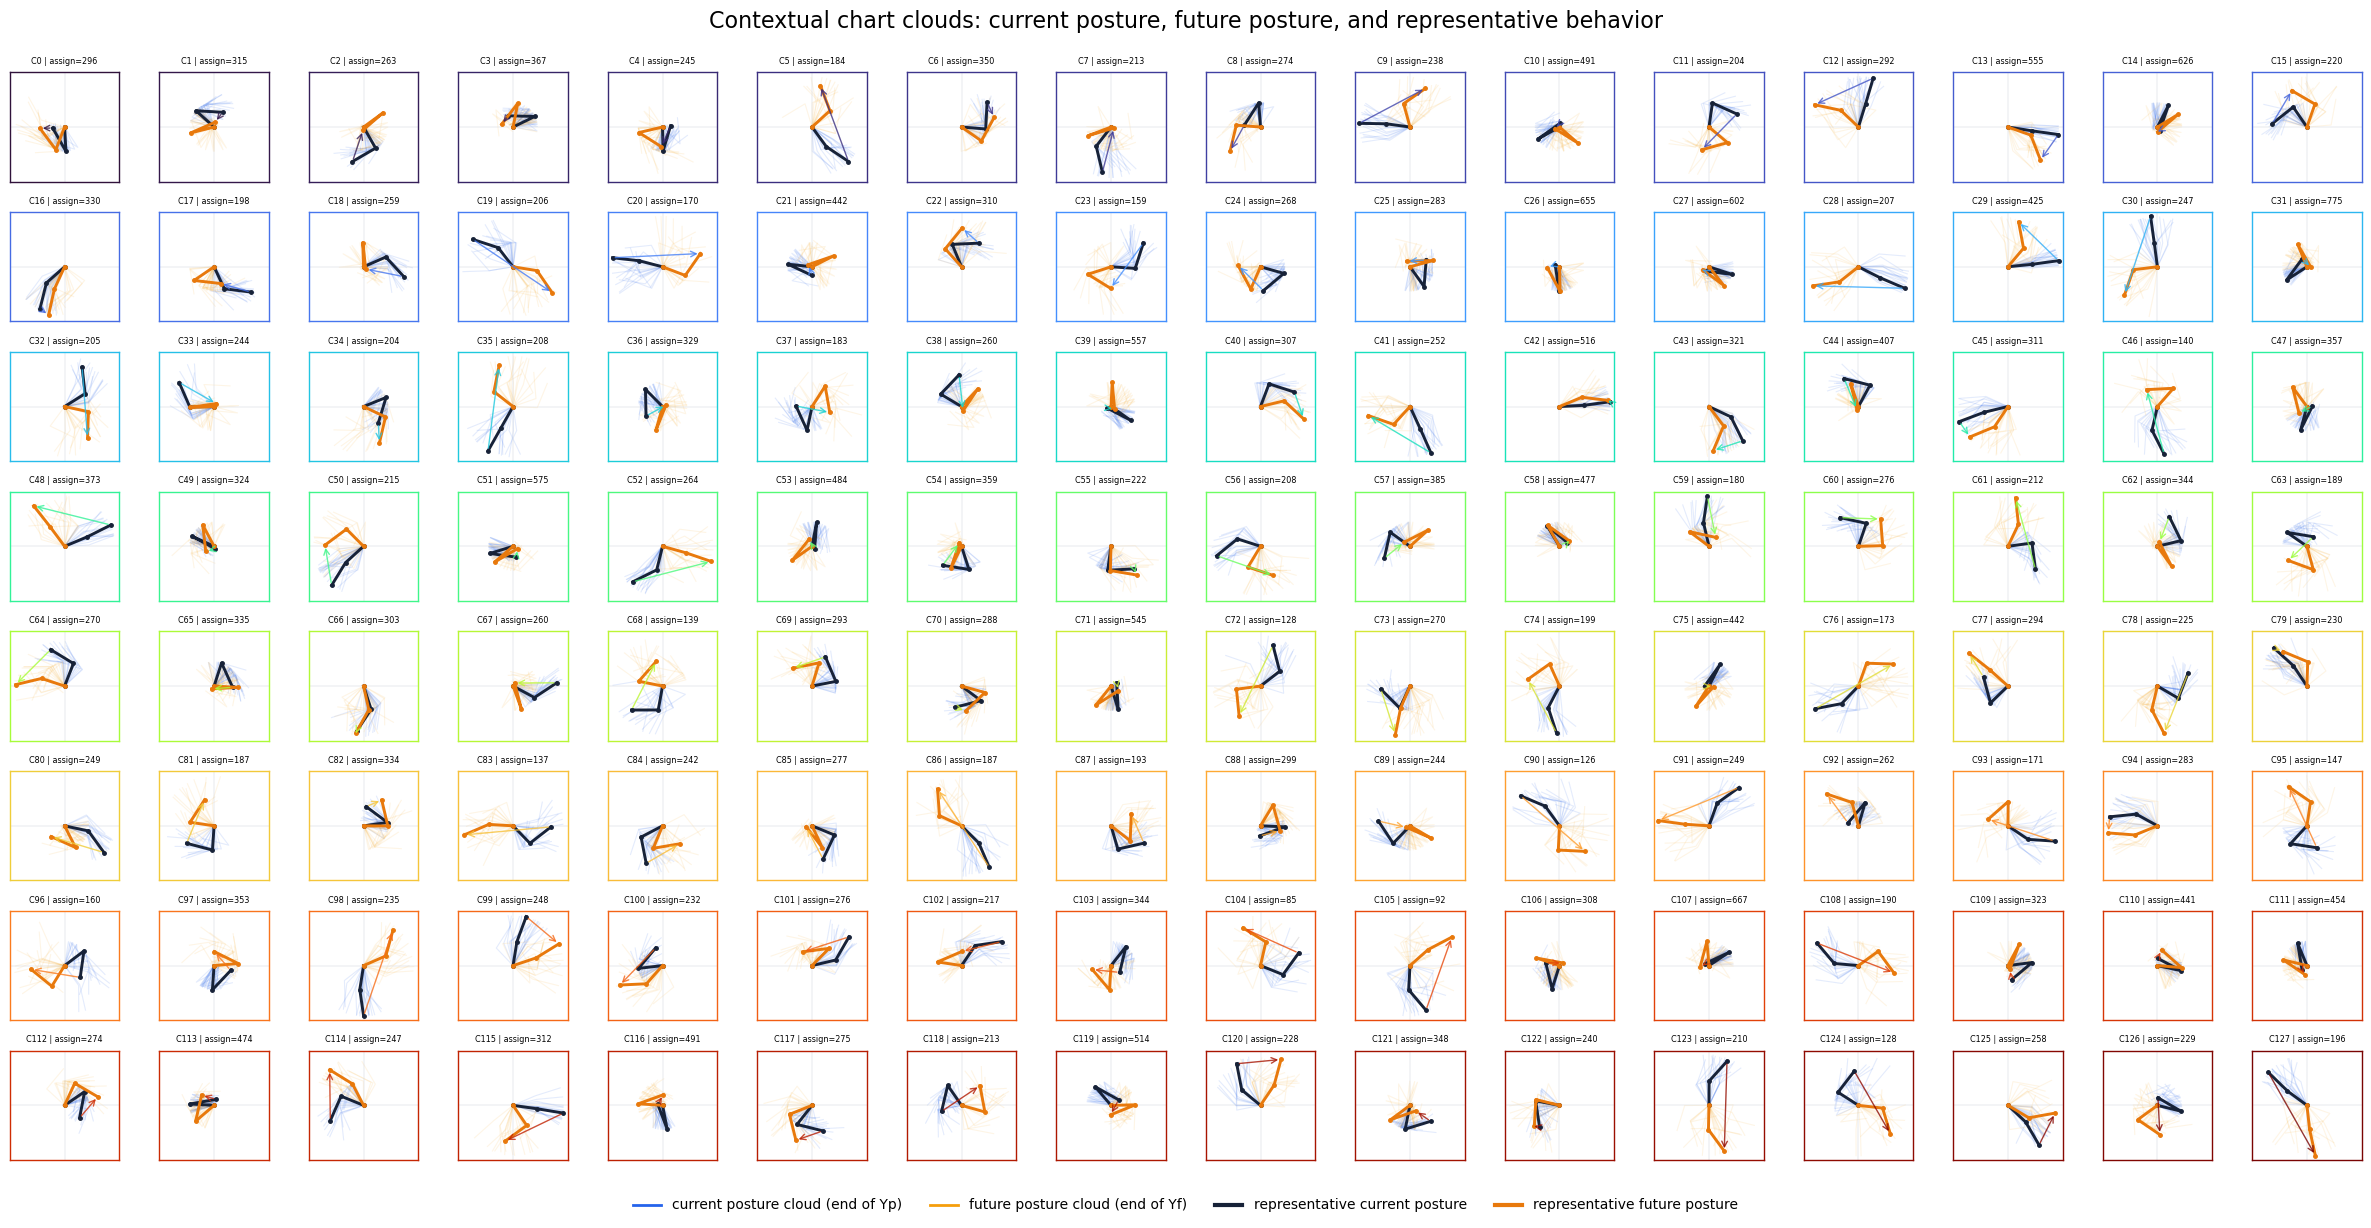

K-means assignment sizes: 85 median 263.5 775
Cached support size per contextual chart: 200


In [4]:
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

library = contextual.prepare_contextual_library(H)
Q = contextual.output_cost(config)
embedding = contextual._contextual_embedding(library, Q)
supports = np.asarray(artifact['support_indices'], dtype=int)
assignment_counts = np.asarray(artifact['assignment_counts'], dtype=int)
Y_windows = H[routed.pipe.M * routed.pipe.L:].reshape(
    routed.pipe.L, routed.pipe.P, H.shape[1]
)
current_states = Y_windows[routed.pipe.T_INI - 1].T
future_states = Y_windows[-1].T

def arm_segments(states):
    states = np.asarray(states)
    elbows = 0.10 * np.column_stack([states[:, 0], states[:, 2]])
    fingertips = states[:, 6:8]
    return np.stack([np.zeros_like(elbows), elbows, fingertips], axis=1)

rng = np.random.default_rng(29)
chart_colors = plt.cm.turbo(np.linspace(0, 1, supports.shape[0]))
fig, axes = plt.subplots(8, 16, figsize=(24, 12.5))
fig.subplots_adjust(left=0.006, right=0.994, bottom=0.06, top=0.93,
                    wspace=0.16, hspace=0.28)
for chart_id, ax in enumerate(axes.flat):
    support = supports[chart_id]
    sample = rng.choice(support, size=min(18, support.size), replace=False)
    prototype = embedding[support].mean(axis=0)
    representative = support[np.argmin(np.linalg.norm(embedding[support] - prototype, axis=1))]

    ax.add_collection(LineCollection(
        arm_segments(current_states[sample]), colors='#2563EB', linewidths=0.8,
        alpha=0.12, zorder=1,
    ))
    ax.add_collection(LineCollection(
        arm_segments(future_states[sample]), colors='#F59E0B', linewidths=0.8,
        alpha=0.10, zorder=1,
    ))
    current_arm = arm_segments(current_states[[representative]])[0]
    future_arm = arm_segments(future_states[[representative]])[0]
    ax.plot(current_arm[:, 0], current_arm[:, 1], '-o', color='#172238',
            linewidth=2.1, markersize=2.5, zorder=3)
    ax.plot(future_arm[:, 0], future_arm[:, 1], '-o', color='#E8790C',
            linewidth=2.1, markersize=2.5, zorder=3)
    ax.annotate('', xy=future_arm[-1], xytext=current_arm[-1],
                arrowprops=dict(arrowstyle='->', color=chart_colors[chart_id],
                                linewidth=1.0, alpha=0.8))
    ax.axhline(0, color='#d1d5db', linewidth=0.35)
    ax.axvline(0, color='#d1d5db', linewidth=0.35)
    ax.set_xlim(-0.225, 0.225)
    ax.set_ylim(-0.225, 0.225)
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'C{chart_id} | assign={assignment_counts[chart_id]}', fontsize=5.8)
    for spine in ax.spines.values():
        spine.set_color(chart_colors[chart_id])
        spine.set_linewidth(1.0)

fig.suptitle('Contextual chart clouds: current posture, future posture, and representative behavior', fontsize=16)
fig.legend(handles=[
    Line2D([0], [0], color='#2563EB', linewidth=2, label='current posture cloud (end of Yp)'),
    Line2D([0], [0], color='#F59E0B', linewidth=2, label='future posture cloud (end of Yf)'),
    Line2D([0], [0], color='#172238', linewidth=3, label='representative current posture'),
    Line2D([0], [0], color='#E8790C', linewidth=3, label='representative future posture'),
], loc='lower center', bbox_to_anchor=(0.5, 0.008), ncol=4, frameon=False)
context_cloud_path = RESULT_ROOT / 'contextual128_chart_configuration_clouds.png'
fig.savefig(context_cloud_path, dpi=150, bbox_inches='tight')
plt.show()
print('K-means assignment sizes:', int(assignment_counts.min()),
      f"median {np.median(assignment_counts):.1f}", int(assignment_counts.max()))
print('Cached support size per contextual chart:', supports.shape[1])

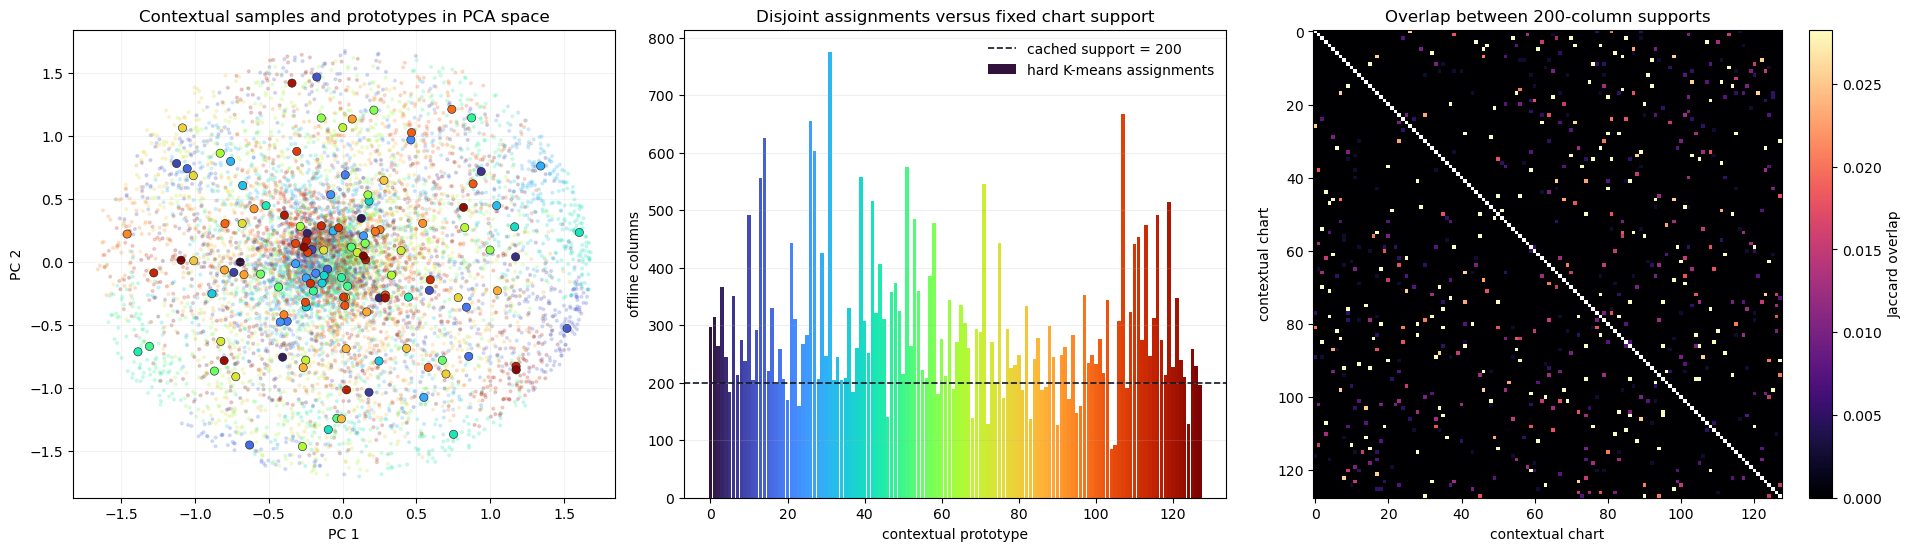

PCA variance captured: 41.9%
Chart pairs with overlapping supports: 317
Median positive Jaccard overlap: 0.0127


In [5]:
from sklearn.decomposition import PCA
from sklearn.metrics import pairwise_distances_argmin_min

sample_indices = np.linspace(0, embedding.shape[0] - 1, 8000, dtype=int)
sample_embedding = embedding[sample_indices]
prototype_embedding = np.vstack([embedding[support].mean(axis=0) for support in supports])
pca = PCA(n_components=2, random_state=0)
sample_pca = pca.fit_transform(sample_embedding)
prototype_pca = pca.transform(prototype_embedding)
sample_labels, _ = pairwise_distances_argmin_min(sample_embedding, prototype_embedding)

membership = np.zeros((supports.shape[0], H.shape[1]), dtype=np.int16)
for chart_id, support in enumerate(supports):
    membership[chart_id, support] = 1
intersections = membership @ membership.T
unions = 2 * supports.shape[1] - intersections
jaccard = intersections / np.maximum(unions, 1)
np.fill_diagonal(jaccard, np.nan)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.4), constrained_layout=True)
axes[0].scatter(sample_pca[:, 0], sample_pca[:, 1], c=sample_labels,
                cmap='turbo', s=4, alpha=0.18)
axes[0].scatter(prototype_pca[:, 0], prototype_pca[:, 1], c=chart_colors,
                s=35, edgecolor='#111827', linewidth=0.4)
axes[0].set_title('Contextual samples and prototypes in PCA space')
axes[0].set_xlabel('PC 1')
axes[0].set_ylabel('PC 2')
axes[0].grid(alpha=0.15)

axes[1].bar(np.arange(assignment_counts.size), assignment_counts,
            color=chart_colors, width=0.9, label='hard K-means assignments')
axes[1].axhline(supports.shape[1], color='#111827', linestyle='--',
                linewidth=1.2, label='cached support = 200')
axes[1].set_title('Disjoint assignments versus fixed chart support')
axes[1].set_xlabel('contextual prototype')
axes[1].set_ylabel('offline columns')
axes[1].legend(frameon=False)
axes[1].grid(axis='y', alpha=0.2)

image = axes[2].imshow(jaccard, cmap='magma', vmin=0, vmax=np.nanpercentile(jaccard, 99))
axes[2].set_title('Overlap between 200-column supports')
axes[2].set_xlabel('contextual chart')
axes[2].set_ylabel('contextual chart')
fig.colorbar(image, ax=axes[2], label='Jaccard overlap', fraction=0.046)

diagnostic_path = RESULT_ROOT / 'contextual128_atlas_diagnostics.png'
fig.savefig(diagnostic_path, dpi=160, bbox_inches='tight')
plt.show()
positive_overlap = jaccard[np.isfinite(jaccard) & (jaccard > 0)]
print('PCA variance captured:', f'{100*pca.explained_variance_ratio_.sum():.1f}%')
print('Chart pairs with overlapping supports:', int(np.sum(np.triu(np.nan_to_num(jaccard) > 0, 1))))
print('Median positive Jaccard overlap:', f'{np.median(positive_overlap):.4f}')

### How to read these views

- The physical charts form the routing partition. Their labels define graph nodes and observed directed transitions.
- The contextual prototypes live in a past/future output space. A contextual chart therefore represents a family of motions, not one target or one static posture.
- `assign` is the size of the disjoint K-means Voronoi cluster. Every cached control support nevertheless contains exactly 200 nearest complete Hankel columns, so supports may overlap.
- The PCA panel is only a two-dimensional projection. The controller scores prototypes in the complete normalized $Y_p/Y_f$ context space.
- No chart contains a stabilized target episode: all columns come from the same random-walk offline library used by the physical baseline.

## 3. Fairness audit

The offline library contains only random-action episodes. Goal construction excludes candidates whose source environment target is within 6 cm of the online target. Contextual prototypes and their supports are frozen before evaluation. Online deployment scores 128 prototypes, not all offline trajectories, and performs no online SVD, model fitting, inverse kinematics, or feedback fallback.

In [6]:
primary_runs = development_runs + evaluation_runs
audit = evaluation_summary['fairness_audit']
minimum_source_target_separation = min(
    row['data_goal_source_target_distance'] for row in primary_runs
)

assert audit['offline_stabilized_episode_count'] == 0
assert minimum_source_target_separation >= config.goal_source_target_min_distance
assert all(row['fitted_dynamics_model'] is False for row in primary_runs)
assert all(row['online_nearest_trajectory_retrieval'] is False for row in primary_runs)
assert all(row['online_svd_rebuild'] is False for row in primary_runs)
assert all(row['online_hankel_columns_scored'] == 0 for row in primary_runs)
assert all(row['use_ik_ref'] is False for row in primary_runs)
assert all(row['feedback_fallback'] is False for row in primary_runs)

display(pd.Series({
    'offline seed range': str(audit['data_seed_range']),
    'stabilized offline episodes': audit['offline_stabilized_episode_count'],
    'best offline final-tail mean (m)': audit['offline_best_tail_mean'],
    'minimum goal-source target separation (m)': minimum_source_target_separation,
    'required source-target separation (m)': config.goal_source_target_min_distance,
    'online objects scored': '128 contextual prototypes',
    'online Hankel-column retrieval / SVD': 'none / none',
    'fitted dynamics / IK / feedback fallback': 'none / none / none',
}))

offline seed range                                        [2026, 2225]
stabilized offline episodes                                          0
best offline final-tail mean (m)                              0.029331
minimum goal-source target separation (m)                     0.060238
required source-target separation (m)                             0.06
online objects scored                        128 contextual prototypes
online Hankel-column retrieval / SVD                       none / none
fitted dynamics / IK / feedback fallback            none / none / none
dtype: object

## 4. Frozen 500-seed evaluation

Strict success requires both the final-30 and final-100 windows to have mean distance below 1 cm and maximum distance below 2 cm. Seeds 211–710 use the same frozen random-walk data, physical graph, goal construction, DeePC QP, and success definition as the physical baseline.

In [7]:
def strict_success(result):
    return bool(result['success_30'] and result['success_100'])

def wilson_interval(successes, trials, z=1.959963984540054):
    rate = successes / trials
    denominator = 1 + z*z/trials
    center = (rate + z*z/(2*trials)) / denominator
    half_width = z*np.sqrt(rate*(1-rate)/trials + z*z/(4*trials**2)) / denominator
    return center-half_width, center+half_width

results = pd.DataFrame([{
    'seed': row['seed'],
    'final-30 mean (mm)': 1000*row['mean_last_30'],
    'final-100 mean (mm)': 1000*row['mean_last_100'],
    'minimum (mm)': 1000*row['minimum'],
    'strict success': strict_success(row),
    'contextual triggered': row['contextual_triggered'],
    'trigger index (0-based)': row['contextual_trigger_step'],
    'contextual fraction': row['contextual_usage_fraction'],
} for row in evaluation_runs])
successes = int(results['strict success'].sum())
ci_low, ci_high = wilson_interval(successes, len(results))
baseline_by_seed = {int(row['seed']): row for row in baseline_summary['results']}
baseline_successes = sum(strict_success(baseline_by_seed[s]) for s in evaluation_seeds)

summary_table = pd.DataFrame([
    {'method': 'Physical Atlas-DeePC', 'seeds': 500, 'successes': baseline_successes,
     'success rate': baseline_successes/500},
    {'method': 'Triggered contextual Atlas-DeePC', 'seeds': 500, 'successes': successes,
     'success rate': successes/500},
]).set_index('method')
display(summary_table.style.format({'success rate': '{:.1%}'}))

failures = results.loc[~results['strict success']].copy()
failures['failure type'] = np.select(
    [failures['minimum (mm)'] < 10, failures['minimum (mm)'] < 20],
    ['within 1 cm; did not stabilize', 'within 2 cm; did not stabilize'],
    default='never reached 2 cm',
)
display(failures[['seed','failure type','minimum (mm)','final-30 mean (mm)',
                  'trigger index (0-based)','contextual fraction']].style.format({
    'minimum (mm)': '{:.2f}', 'final-30 mean (mm)': '{:.2f}',
    'contextual fraction': '{:.1%}',
}))
print('Contextual Atlas:', f'{successes}/500 = {successes/500:.1%}')
print('95% Wilson interval:', f'[{100*ci_low:.1f}%, {100*ci_high:.1f}%]')
print('Triggered rollouts:', int(results['contextual triggered'].sum()), '/ 500')
print('Mean contextual usage over all rollouts:', f"{results['contextual fraction'].mean():.1%}")

,seeds,successes,success rate
method,,,
Physical Atlas-DeePC,500,443,88.6%
Triggered contextual Atlas-DeePC,500,480,96.0%


,seed,failure type,minimum (mm),final-30 mean (mm),trigger index (0-based),contextual fraction
20,231,within 1 cm; did not stabilize,1.41,16.08,52,83.8%
34,245,within 1 cm; did not stabilize,4.41,14.80,41,87.2%
41,252,never reached 2 cm,29.72,45.76,41,87.2%
66,277,never reached 2 cm,40.60,60.51,45,85.9%
158,369,within 2 cm; did not stabilize,13.10,16.35,51,84.1%
185,396,within 1 cm; did not stabilize,1.27,35.61,90,71.9%
194,405,within 1 cm; did not stabilize,1.11,10.72,69,78.4%
208,419,never reached 2 cm,48.04,59.24,37,88.4%
212,423,within 1 cm; did not stabilize,1.68,11.65,49,84.7%
233,444,never reached 2 cm,25.78,40.32,40,87.5%


Contextual Atlas: 480/500 = 96.0%
95% Wilson interval: [93.9%, 97.4%]
Triggered rollouts: 59 / 500
Mean contextual usage over all rollouts: 9.9%


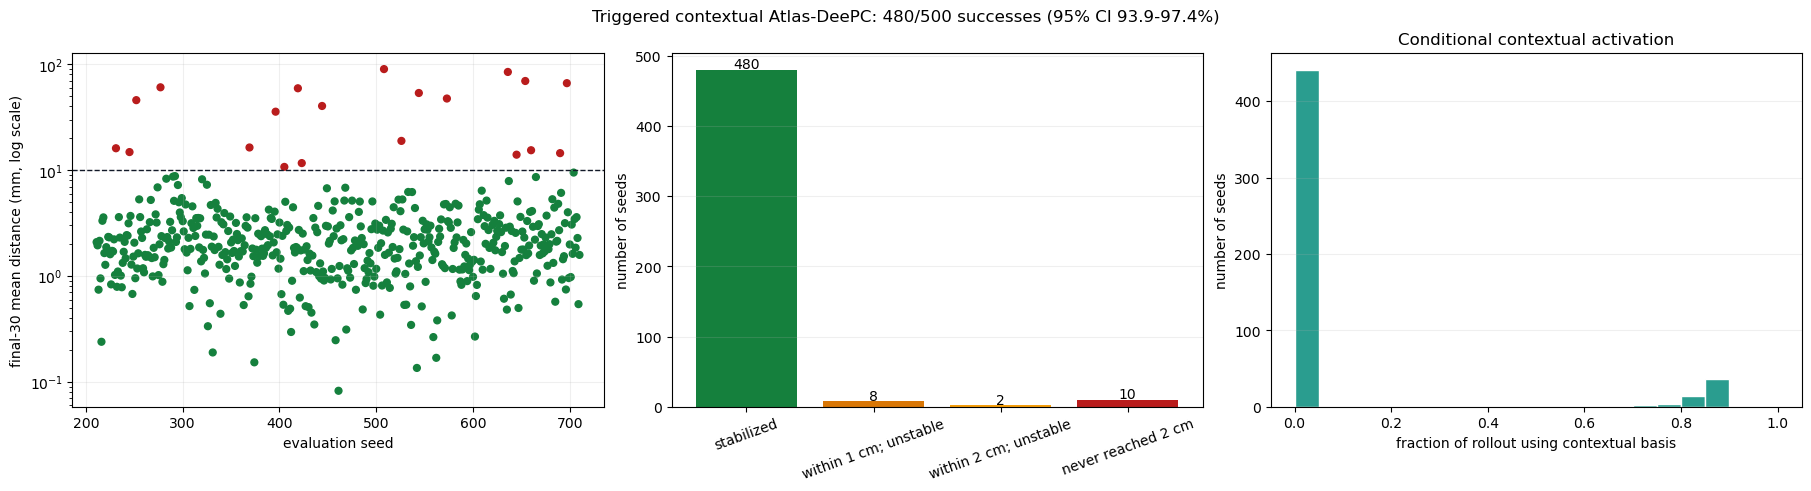

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), constrained_layout=True)
colors = np.where(results['strict success'], '#15803d', '#b91c1c')
axes[0].scatter(results['seed'], results['final-30 mean (mm)'], c=colors, s=24)
axes[0].axhline(10, color='#111827', linestyle='--', linewidth=1)
axes[0].set_yscale('log')
axes[0].set_xlabel('evaluation seed')
axes[0].set_ylabel('final-30 mean distance (mm, log scale)')
axes[0].grid(alpha=0.2)

failure_counts = pd.Series({
    'stabilized': successes,
    'within 1 cm; unstable': int((failures['minimum (mm)'] < 10).sum()),
    'within 2 cm; unstable': int(((failures['minimum (mm)'] >= 10) &
                                    (failures['minimum (mm)'] < 20)).sum()),
    'never reached 2 cm': int((failures['minimum (mm)'] >= 20).sum()),
})
axes[1].bar(failure_counts.index, failure_counts.values,
            color=['#15803d','#d97706','#f59e0b','#b91c1c'])
axes[1].tick_params(axis='x', rotation=20)
axes[1].set_ylabel('number of seeds')
axes[1].grid(axis='y', alpha=0.2)
for index, value in enumerate(failure_counts):
    axes[1].text(index, value+2, str(value), ha='center')

axes[2].hist(results['contextual fraction'], bins=np.linspace(0, 1, 21),
             color='#2a9d8f', edgecolor='white')
axes[2].set_xlabel('fraction of rollout using contextual basis')
axes[2].set_ylabel('number of seeds')
axes[2].set_title('Conditional contextual activation')
axes[2].grid(axis='y', alpha=0.2)

fig.suptitle(f'Triggered contextual Atlas-DeePC: {successes}/500 successes '
             f'(95% CI {100*ci_low:.1f}-{100*ci_high:.1f}%)')
statistics_path = RESULT_ROOT / 'contextual128_500_statistics.png'
fig.savefig(statistics_path, dpi=160, bbox_inches='tight')
plt.show()

### Online computation

Before the trigger, contextual scoring is skipped and the controller uses the physical-chart cache. After triggering, only 128 prototype summaries are scored; the selected rank-60 basis is already cached. The timings below are measured inside the saved 500-seed deployments and should be interpreted as workload measurements rather than a controlled single-process benchmark.

In [9]:
timing_table = pd.DataFrame([{
    'stage': 'physical localization',
    'median across rollouts (ms)': np.median([r['median_localization_ms'] for r in evaluation_runs]),
}, {
    'stage': 'graph routing',
    'median across rollouts (ms)': np.median([r['median_routing_ms'] for r in evaluation_runs]),
}, {
    'stage': 'contextual prototype scoring',
    'median across rollouts (ms)': np.median([r['median_cluster_scoring_ms'] for r in evaluation_runs]),
}, {
    'stage': 'cached matrix preparation',
    'median across rollouts (ms)': np.median([r['median_matrix_preparation_ms'] for r in evaluation_runs]),
}, {
    'stage': 'DeePC QP solve',
    'median across rollouts (ms)': np.median([r['median_solve_ms'] for r in evaluation_runs]),
}, {
    'stage': 'total control computation',
    'median across rollouts (ms)': np.median([r['median_control_compute_ms'] for r in evaluation_runs]),
}]).set_index('stage')
display(timing_table.style.format('{:.3f}'))

,median across rollouts (ms)
stage,
physical localization,0.067
graph routing,0.014
contextual prototype scoring,0.001
cached matrix preparation,0.001
DeePC QP solve,51.823
total control computation,52.000


## 5. Exact MuJoCo replay gallery

The numerical statistics use all 500 saved rollouts. The videos below replay selected saved input sequences in MuJoCo and verify that every reconstructed output matches the saved numerical rollout to at most $10^{-8}$. The set mixes nominal physical-atlas successes, context-triggered rescues, and diagnostic failures.

In [10]:
def video_gallery(summary, experiment_dir, seeds, title):
    rows = {int(row['seed']): row for row in summary['results']}
    cards = []
    for seed in seeds:
        row = rows[seed]
        video_path = (experiment_dir / f'seed{seed}_control.mp4').resolve()
        audit_path = experiment_dir / f'seed{seed}_control_video_verification.json'
        audit = json.loads(audit_path.read_text())
        assert audit['maximum_replay_output_error'] <= 1e-8
        assert video_path.exists()
        success = strict_success(row)
        status = 'SUCCESS' if success else 'FAILURE'
        color = '#166534' if success else '#b91c1c'
        trigger = (f"trigger {row['contextual_trigger_step']}" if row['contextual_triggered']
                   else 'physical basis only')
        cards.append(f'''
        <div style="border:1px solid #d1d5db; padding:10px; background:#fff;">
          <div style="font:600 14px sans-serif; color:#111827; margin-bottom:6px;">
            Seed {seed} &nbsp; <span style="color:{color}">{status}</span>
          </div>
          <div style="font:12px sans-serif; color:#4b5563; margin-bottom:8px;">
            Final-30 mean: {1000*row['mean_last_30']:.3f} mm &nbsp; {trigger}
          </div>
          <video src="{video_path}" controls loop preload="metadata" style="width:100%; max-width:360px;">
            Your browser does not support the video element.
          </video>
        </div>
        ''')
    return HTML(f'''
    <h3 style="font-family:sans-serif">{title}</h3>
    <div style="display:grid; grid-template-columns:repeat(auto-fit,minmax(280px,1fr)); gap:12px;">
      {''.join(cards)}
    </div>
    ''')

success_video_seeds = [215, 222, 232, 247, 266, 288, 319, 404, 542, 600]
diagnostic_video_seeds = [232, 231, 277]
display(video_gallery(evaluation_summary, EVAL_CONTEXTUAL_DIR, success_video_seeds,
                      'Ten representative contextual-Atlas successes'))
display(video_gallery(evaluation_summary, EVAL_CONTEXTUAL_DIR, diagnostic_video_seeds,
                      'Contextual rescue and failure diagnostics'))

## 6. Slowed contextual-routing dashboard

Seed 232 is a particularly informative rescue. The physical baseline reached the target neighborhood and later drifted, whereas triggered contextual Atlas-DeePC activates its contextual basis at step 90 and stabilizes with a final-100 mean of 0.791 mm. The dashboard is displayed at **0.25x play speed**.

The upper-right panel always shows the physical graph route. Its green shaded interval marks contextual-basis activation. The live status line names either the physical chart matrix or the selected contextual prototype matrix supplied to DeePC.

In [11]:
def dashboard_path(seed, label):
    return DASHBOARD_DIR / f'contextual128_seed{seed}_{label}_025x.mp4'

main_video = dashboard_path(232, 'rescued').resolve()
main_poster = main_video.with_name(f'{main_video.stem}_poster.png')
main_metadata = json.loads(main_video.with_suffix('.json').read_text())
assert main_video.exists() and main_poster.exists()
display(HTML(f'''
<video src="{main_video}" poster="{main_poster}" controls preload="metadata"
       style="width:100%; max-width:1280px; border:1px solid #2a9d8f; background:#f5f7fa;">
  Your browser does not support the video element.
</video>
'''))
print(f"Seed 232 | trigger step {main_metadata['contextual_trigger_step'] + 1} | "
      f"displayed contextual fraction {main_metadata['contextual_usage_fraction_displayed']:.1%} | "
      f"final displayed error {main_metadata['final_error_mm']:.3f} mm")

Seed 232 | trigger step 91 | displayed contextual fraction 35.7% | final displayed error 0.708 mm


### Direct paired rescues: baseline failure versus contextual success

Each row below uses the **same seed, initial arm state, online target, offline dataset, physical graph, reference generator, constraints, and DeePC objective**. The left video uses only the physical chart basis. The right video introduces the contextual chart basis after the causal terminal-stall trigger. Thus, the visual difference isolates the online basis-selection change.

In [12]:
paired_rescue_seeds = [232, 247, 266]
paired_cards = []
for seed in paired_rescue_seeds:
    baseline_row = baseline_by_seed[seed]
    contextual_row = rows[seed] if 'rows' in globals() else evaluation_by_seed[seed]
    baseline_video = (BASELINE_DASHBOARD_DIR / f'physical48_seed{seed}_failure_025x.mp4').resolve()
    baseline_poster = baseline_video.with_name(f'{baseline_video.stem}_poster.png')
    contextual_video = dashboard_path(seed, 'rescued').resolve()
    contextual_poster = contextual_video.with_name(f'{contextual_video.stem}_poster.png')
    assert all(path.exists() for path in [baseline_video, baseline_poster,
                                          contextual_video, contextual_poster])
    paired_cards.append(f'''
    <section style="border:1px solid #cbd5e1; padding:12px; margin:0 0 18px; background:#f8fafc;">
      <h4 style="font:700 16px sans-serif; margin:0 0 10px; color:#172238;">Seed {seed}</h4>
      <div style="display:grid; grid-template-columns:repeat(2,minmax(0,1fr)); gap:14px;">
        <div style="background:#fff; border-top:4px solid #b91c1c; padding:8px;">
          <div style="font:600 14px sans-serif; margin-bottom:7px; color:#991b1b;">
            Physical Atlas baseline: FAILURE
            <span style="font-weight:400; color:#4b5563;"> | final-30 mean {1000*baseline_row['mean_last_30']:.3f} mm</span>
          </div>
          <video src="{baseline_video}" poster="{baseline_poster}" controls preload="metadata"
                 style="display:block; width:100%; background:#f5f7fa;"></video>
        </div>
        <div style="background:#fff; border-top:4px solid #15803d; padding:8px;">
          <div style="font:600 14px sans-serif; margin-bottom:7px; color:#166534;">
            Triggered contextual Atlas: SUCCESS
            <span style="font-weight:400; color:#4b5563;"> | final-30 mean {1000*contextual_row['mean_last_30']:.3f} mm</span>
          </div>
          <video src="{contextual_video}" poster="{contextual_poster}" controls preload="metadata"
                 style="display:block; width:100%; background:#f5f7fa;"></video>
        </div>
      </div>
    </section>
    ''')
display(HTML(''.join(paired_cards)))

In [13]:
additional_dashboards = [
    (215, 'nominal'), (247, 'rescued'), (266, 'rescued'),
    (404, 'rescued'), (542, 'rescued'),
]
rows = {int(row['seed']): row for row in evaluation_runs}
cards = []
for seed, label in additional_dashboards:
    video = dashboard_path(seed, label).resolve()
    poster = video.with_name(f'{video.stem}_poster.png')
    metadata = json.loads(video.with_suffix('.json').read_text())
    assert video.exists() and poster.exists()
    trigger = (f"trigger step {metadata['contextual_trigger_step'] + 1}"
               if metadata['contextual_trigger_step'] >= 0 else 'physical basis only')
    cards.append(f'''
    <div style="border:1px solid #d1d5db; padding:10px; background:#fff; color:#111827;">
      <div style="font:600 14px sans-serif; margin-bottom:8px;">
        Seed {seed} &nbsp; <span style="font-weight:400; color:#4b5563;">
        {trigger}; final-30 mean {1000*rows[seed]['mean_last_30']:.3f} mm</span>
      </div>
      <video src="{video}" poster="{poster}" controls preload="metadata"
             style="display:block; width:100%; background:#f5f7fa;">
        Your browser does not support the video element.
      </video>
    </div>
    ''')
display(HTML(f'''
<h3 style="font-family:sans-serif">Five additional contextual-Atlas dashboards</h3>
<div style="display:grid; grid-template-columns:repeat(auto-fit,minmax(520px,1fr)); gap:16px;">
{''.join(cards)}
</div>
'''))

### Reached but did not stabilize: seed 231

Seed 231 comes within 1.41 mm, triggers contextual control at step 52, but finishes with a 16.08 mm final-100 mean. It is a useful counterexample: contextual activation is a data-enabled rescue, not a guaranteed terminal stabilizer.

In [14]:
failure_video = dashboard_path(231, 'failure_unstable').resolve()
failure_poster = failure_video.with_name(f'{failure_video.stem}_poster.png')
failure_metadata = json.loads(failure_video.with_suffix('.json').read_text())
assert failure_video.exists() and failure_poster.exists()
display(HTML(f'''
<video src="{failure_video}" poster="{failure_poster}" controls preload="metadata"
       style="width:100%; max-width:1280px; border:1px solid #b91c1c; background:#f5f7fa;">
  Your browser does not support the video element.
</video>
'''))
print('Seed 231 | trigger step', failure_metadata['contextual_trigger_step'] + 1,
      '| final displayed error', f"{failure_metadata['final_error_mm']:.3f} mm")

Seed 231 | trigger step 53 | final displayed error 16.081 mm


### Mechanical route failure: seed 277

Seed 277 remains a failure after contextual activation. The graph’s periodic joint representation requests a posture transition across the $\pm\pi$ boundary that the mechanically limited joint cannot execute. Contextual basis selection changes the behavioral data supplied to DeePC, but it does not alter the physical graph route or repair an infeasible waypoint sequence.

In [15]:
joint_video = dashboard_path(277, 'failure_joint_limit').resolve()
joint_poster = joint_video.with_name(f'{joint_video.stem}_poster.png')
joint_metadata = json.loads(joint_video.with_suffix('.json').read_text())
assert joint_video.exists() and joint_poster.exists()
display(HTML(f'''
<video src="{joint_video}" poster="{joint_poster}" controls preload="metadata"
       style="width:100%; max-width:1280px; border:1px solid #b91c1c; background:#f5f7fa;">
  Your browser does not support the video element.
</video>
'''))
print('Seed 277 | trigger step', joint_metadata['contextual_trigger_step'] + 1,
      '| final displayed error', f"{joint_metadata['final_error_mm']:.3f} mm")

Seed 277 | trigger step 46 | final displayed error 60.506 mm


## 7. Reproduce or extend the contextual evaluation

The cell below is disabled because the complete 500-seed panel is already saved. Change only `EVALUATION_SEEDS` to evaluate another range. The frozen 128-prototype partition and rank-60 cached bases are reused; no videos are rendered by this cell.

In [16]:
RERUN = False
EVALUATION_SEEDS = list(range(711, 721))  # Change only this line; stop is exclusive.
REPRODUCTION_DIR = RESULT_ROOT / 'contextual_atlas_reproduction'
OVERWRITE = False
if RERUN:
    contextual.run_panel(
        EVALUATION_SEEDS,
        PHYSICAL_ATLAS_DIR,
        REPRODUCTION_DIR,
        cluster_config,
        DATA_PATH,
        workers=8,
        overwrite=OVERWRITE,
        control_overrides={'svd_rank': config.svd_rank},
        source_artifact_path=EVAL_CONTEXTUAL_DIR / 'contextual_cluster_atlas.npz',
    )
else:
    print('Using the saved 500-seed contextual evaluation. Set RERUN=True to run new seeds.')

Using the saved 500-seed contextual evaluation. Set RERUN=True to run new seeds.


## Interpretation

Triggered contextual Atlas-DeePC is a conditional two-atlas controller. The physical atlas supplies persistent localization and graph-routed references. Its cached basis also supplies nominal control until measured terminal progress stalls. At that point, the contextual atlas uses current $Y_p$ history and desired $Y_f$ behavior to select one of 128 cached rank-60 bases.

The method improves strict success from 443/500 for physical Atlas-DeePC to 480/500 while retaining a purely behavioral DeePC controller. It scores no full Hankel columns and rebuilds no SVD online. The chart visualizations show the corresponding tradeoff: physical charts are interpretable posture regions, while contextual charts are overlapping past-to-future motion neighborhoods.

The trigger is essential. It preserves reliable physically local behavior during nominal progress and exposes contextual specialization only after evidence of terminal failure. Remaining failures show that behavioral basis selection cannot by itself repair every graph-level mechanical infeasibility or guarantee stabilization when the offline support is inadequate.